## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Adeline Kwakye

**Date:** 10/12/2026

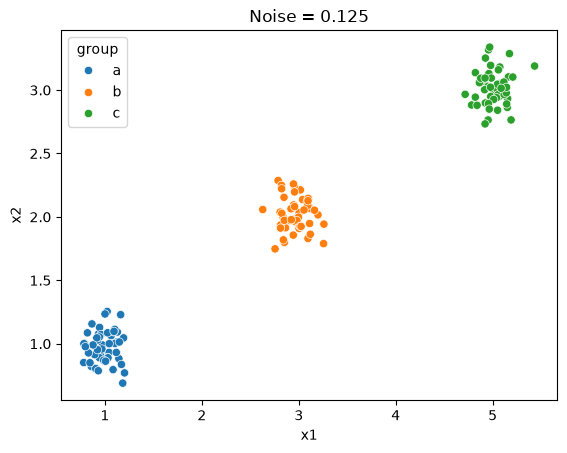

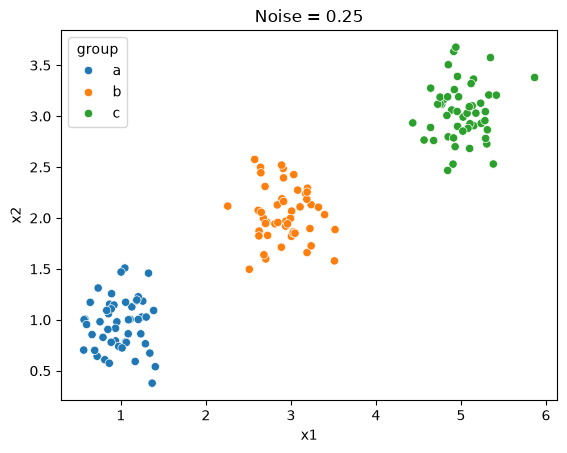

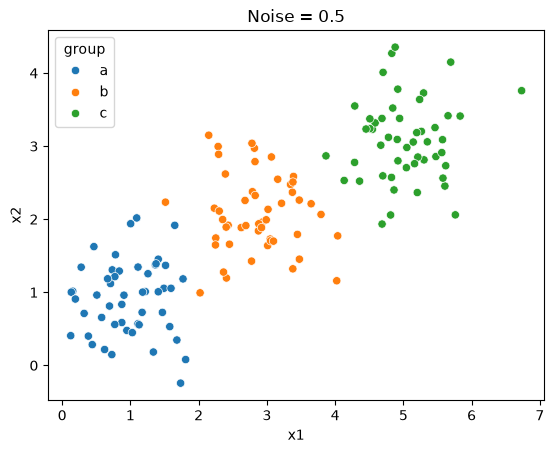

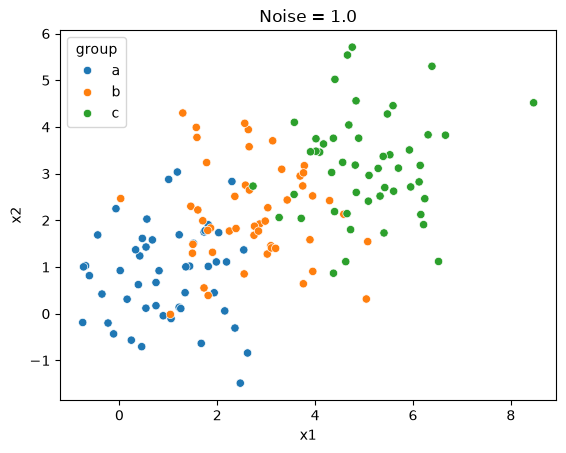

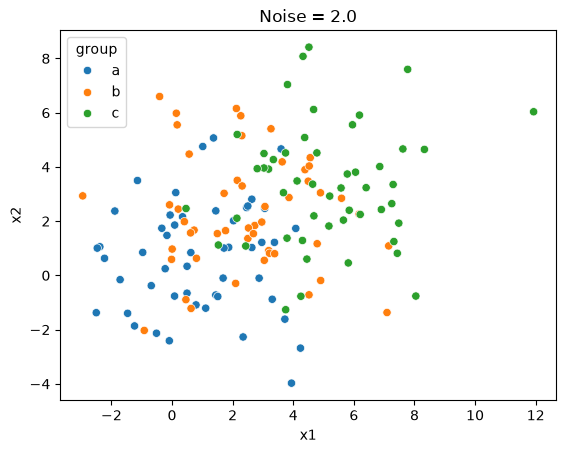

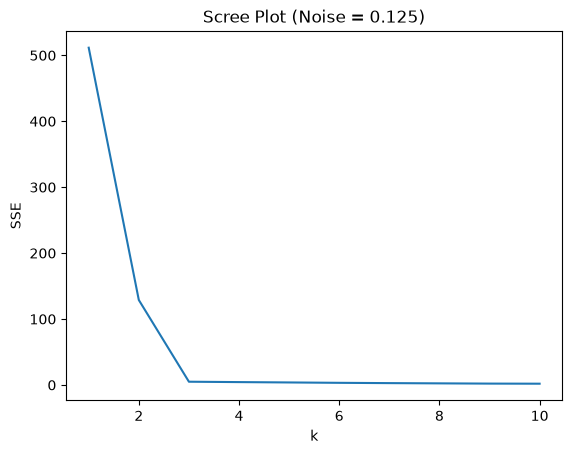

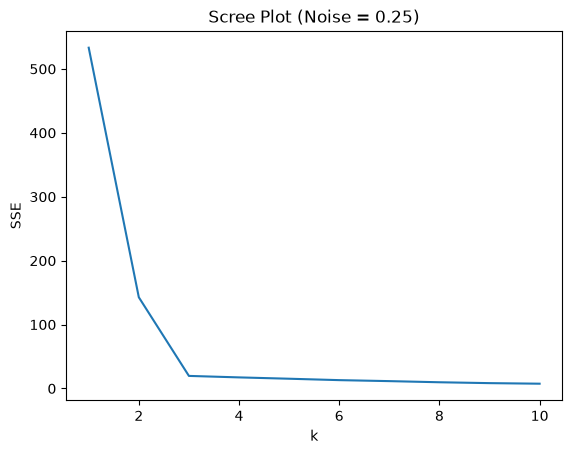

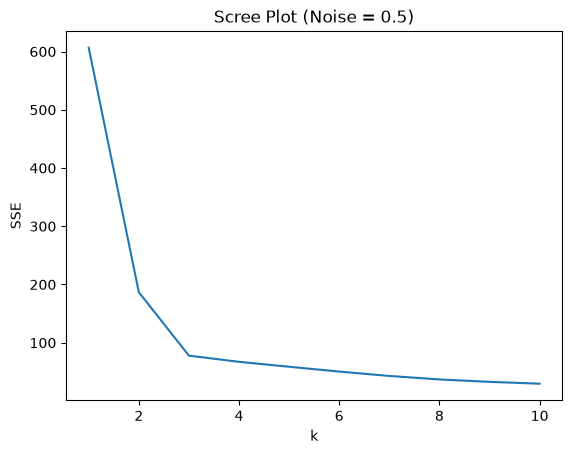

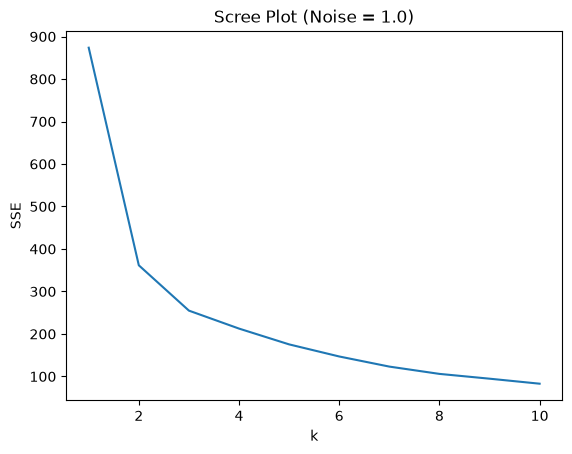

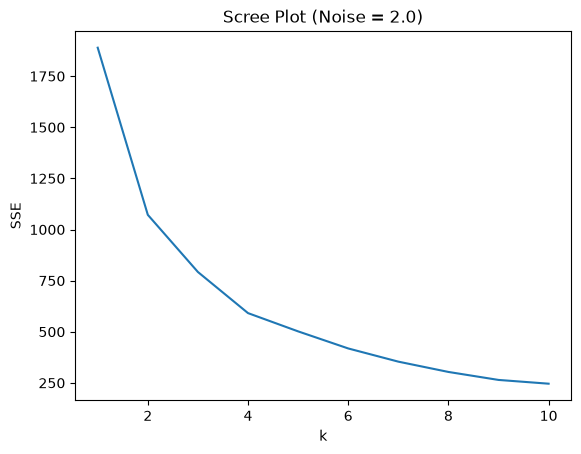

In [5]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# make scatterplot
sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group')
plt.title("Noise = 0.125")
plt.show()
sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group')
plt.title("Noise = 0.25")
plt.show()
sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group')
plt.title("Noise = 0.5")
plt.show()
sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group')
plt.title("Noise = 1.0")
plt.show()
sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group')
plt.title("Noise = 2.0")
plt.show()

# scree plot
X = df0_125[['x1','x2']]
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot (Noise = 0.125)",
    xlabel="k",
    ylabel="SSE"
)

plt.show()

X = df0_25[['x1','x2']]
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot (Noise = 0.25)",
    xlabel="k",
    ylabel="SSE"
)

plt.show()

X = df0_5[['x1','x2']]
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot (Noise = 0.5)",
    xlabel="k",
    ylabel="SSE"
)

plt.show()

X = df1_0[['x1','x2']]
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot (Noise = 1.0)",
    xlabel="k",
    ylabel="SSE"
)

plt.show()

X = df2_0[['x1','x2']]
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot (Noise = 2.0)",
    xlabel="k",
    ylabel="SSE"
)

plt.show()





Q2. At lower noise levels, the three groups are clustered together in their own distinct area, but as noise increases they are seen gradually spreading out to the point where the three groups are all overlaping with each other.

Q3. As noise increases, the elbow of the scree plot becomes less clear. The datasets that have a low noise such as 0.125 and 0.25, the elbow, k = 3, is easy to identify which lets us tknow that 3 clusters was a good choice. However as noise increases, the data points becomes more spread out and the curve becomes less sharp and smoother, making it harder to determine the best number of clusters. Higher noise makes it harder to use the scree plot to choose k. The SSE values also increase with noise, and we can tell that by looking at the tick values on the vertical axis, which causes the vertical scales to differ across the plots.

Q4. The elbow shows the point in which adding more clusters stops significantly reducing the SSE. In this simulation, we see that the elbow is around k=3 because the data has 3 original groups. When k is less than 3, adding clusters allows you to separate the groups and significantly reduce the SSE. However when you increase k, after k = 3, adding more clusters only slightly reduces the SSE because the three groups are already separated, which is why the curve gets flatter after the elbow. 

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5744,5744,2020,Yemen,NaN,NaN,NaN,NaN
5778,5778,2020,"Yemen, North",NaN,NaN,NaN,NaN
5812,5812,2020,Yugoslavia,NaN,NaN,NaN,NaN
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


number of countries:  148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


number of duplicated rows:  0


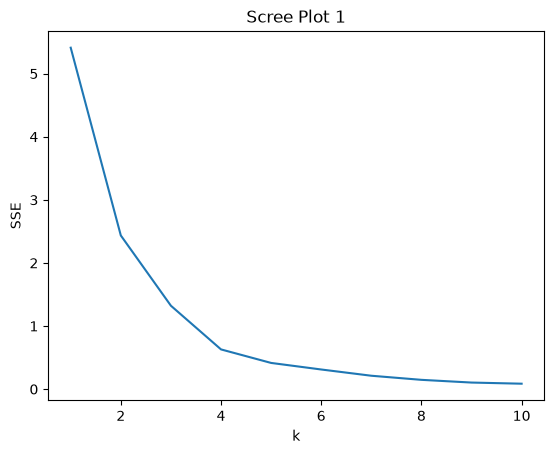

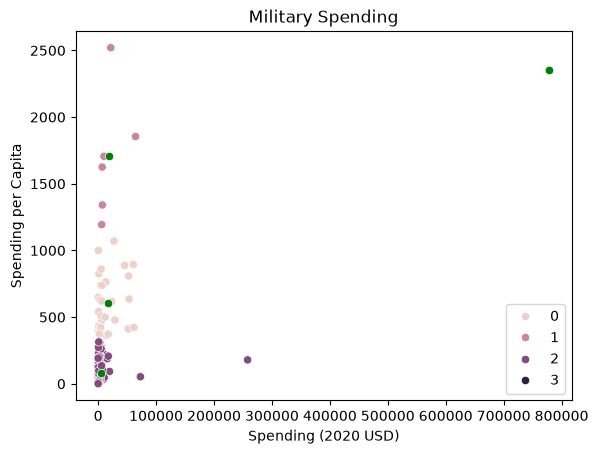

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3


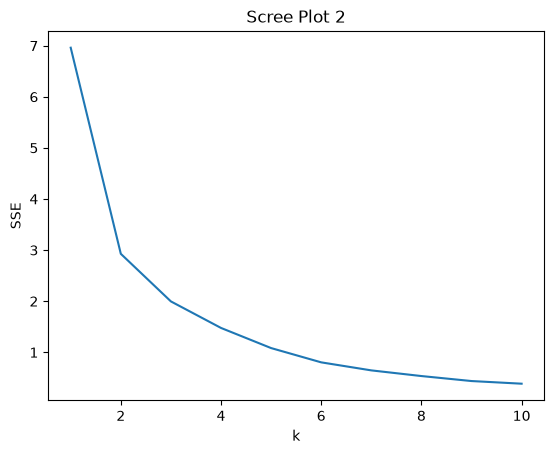

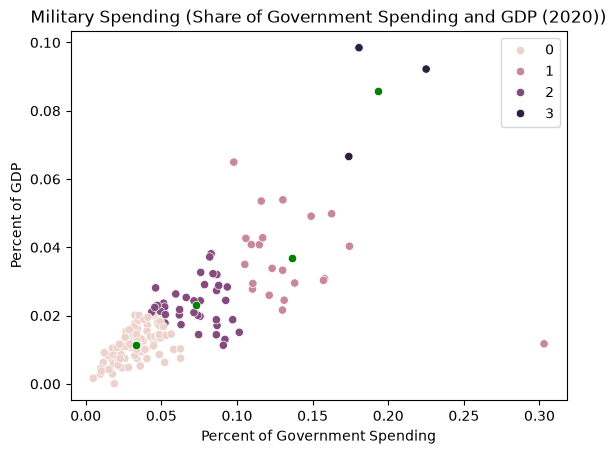

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 86.0  0.033019  0.013198  0.004896   
1                                 22.0  0.136158  0.042661  0.097882   
2                                 37.0  0.072669  0.016870  0.043592   
3                                  3.0  0.193209  0.027779  0.173924   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.022977  0.032821  0.042267  0.062685           86.0  0.011394   
1        0.111561  0.126638  0.146304  0.303027           22.0  0.036932   
2        0.059520  0.075583  0.086497  0.101501           37.0  0.023079   
3        0.177289  0.180654  0.202852  0.225050            3.0  0.085760   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.004816  0.000054  0.007542  0.011341  0.014507  0.020535  
1        0.012381  0.011742  0.029458  0.034419  0.042766  0.064961  
2        0.006411  0.011317  0.018801  0.022408  0.027340  0.038118  
3        0.016886  0.066600  0.079405  0.092211  0.095341  0.098470

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,2


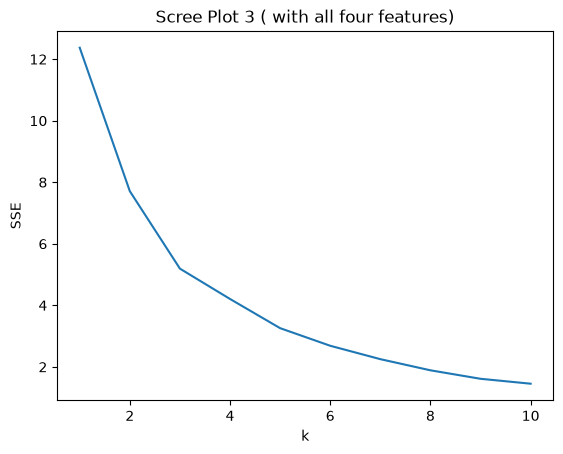

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0   196.926833  267.788506     0.580129   
1                      31.0   212.689100  257.841988    18.297119   
2                       6.0  1875.150751  489.800206  1193.598730   

                                                             \
                 25%          50%          75%          max   
cluster                                                       
0          14.880549    67.083417   295.296094  1341.058851   
1          46.485917   135.459845   217.333791   998.966186   
2        1645.301864  1780.059564  2227.318999  2520.398541   

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                111.0  0.040350  0.019320  0.004896   
1                                 31.0  0.122985  0.043927  0.076005   
2                                  6.0  0.135351  0.055392  0.081976   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.026712  0.037952  0.050505  0.092044          111.0  0.013419   
1        0.093093  0.114776  0.134663  0.303027           31.0  0.033492   
2        0.101034  0.113271  0.164503  0.225050            6.0  0.062634   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1        0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
2        0.028275  0.029429  0.041272  0.059257  0.085398  0.098470

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,2


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# load the csv file
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
df_year_2020 = df[df['Year'] == 2020]  # only year 2020
display(df_year_2020)
df_no_missing = df_year_2020.dropna()
print("number of countries: ",df_no_missing['Country'].value_counts().sum()) # verify number of countries
display(df_no_missing)
print("number of duplicated rows: ",df_no_missing['Country'].duplicated().sum())
df_no_missing.dtypes

# min max scaling spending(2020 USD) and spending per capita
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_no_missing.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins)/ ranges
X.agg(["min", "max"])
# make scree plot
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot 1",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

# scatterplot
model = KMeans(n_clusters = 4, n_init=10, random_state = 0).fit(X)
df_no_missing["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=df_no_missing,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster"
)
sns.scatterplot(x=centers[:,0], y=centers[:,1], color="green", ax=ax)
plt.title("Military Spending")
plt.show()
# describe table
display(df_no_missing.groupby("cluster")[["Spending (2020 USD)", "Spending per Capita"]].describe()
)
display(df_no_missing[df_no_missing["Country"].str.contains("United States", case=False)])



# percent of government spending and percent of gpd

features = ["Percent of Government Spending", "Percent of GDP"]

unscaled = df_no_missing.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins

X = (unscaled - mins) / ranges

X.agg(["min", "max"])

ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot 2",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df_no_missing["cluster"] = model.labels_

centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()

ax = sns.scatterplot(
    data=df_no_missing,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster"
)

sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax
)

plt.title("Military Spending (Share of Government Spending and GDP (2020))")
plt.show()

display(
    df_no_missing.groupby("cluster")[
        ["Percent of Government Spending", "Percent of GDP"]
    ].describe()
)

display(
    df_no_missing[
        df_no_missing["Country"].str.contains("United States", case=False)
    ]
)

# k means clusting with all 4
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df_no_missing.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins)/ ranges
X.agg(["min", "max"])
# make scree plot
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot 3 ( with all four features)",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
df_no_missing["cluster"] = model.labels_

pd.set_option("display.max_columns", None)
display(
    df_no_missing.groupby("cluster")[
        ["Spending (2020 USD)","Spending per Capita","Percent of Government Spending", "Percent of GDP"]
    ].describe()
)
display(
    df_no_missing[
        df_no_missing["Country"].str.contains("United States", case=False)
    ]
)

Q1. No I don't believe additional cleaning was needed since missing values were dropped, and I also went in to check if the data types made sense for the values and if there were any duplicate rows. 

Q2. The describe table shows the four clusters and the difference in total military spending and spending per capita. We're able to see that Cluster 2 contains the most countries with a total of 111 countries, but has the lowest spending per capita. Compared to Cluster 1, which has a total of 6 countries but the highest average spending per capita. Cluster 3 only contains the United States and that has the highest total military spending. K-means placed the United States in its own cluster due to the fact that its total spending was much higher than the other countries. I think that the clusters are showing that countries differ in both their military spending and their spending per capita. 

Q3. Cluster 0, while containing the most countries, 86, it has the lowest average percentages, while Cluster 3 with only 3 countries has the highest average percentages. The united states is in cluster 2 in this analysis. We're able to see that when clustering countries based on their relative military spending we get different groupings compared to clustering them by total spending and spending per capita. It's possible for a country to spend a large amount of money on its military without necessarily spending a larger percentage of its government budget on the military.

Q4. This time around when using 4 variables, three clusters seemed to be a better fit. I was able to see that despite Cluster 0 and 1 having the most countries it had significantly lower military spending compared to Cluster 2 who only had 6 countries but had generally the highest military spending as a whole. Compared to the previous analyses, when using all four variables, it has more factors to consider including the total amount spent on military as well as the share of the government spending and GDP devoted to it. Because it has more factors to consider, it resulted in there being different clusters memberships because the countries were grouped based on all four of those measures as opposed to only two.

Q5. Yes, the K-MC clustering found useful patterns. Through this I was able to see that most countries fell into clusters with lower military spending, while only a few countries were grouped in the group that had the highest spending and devoted more percentages of their government budgest and GDP to the military. Along with that, the results also show that clustering is impacted based on the variables that are used. This shows us that you can't just look at two measures or three measures or even four measures, because depending on how you group them you get different results, which might tell you something different.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 5e567e7bc3ddbb6acd49d9205b05ea3def2b7fa0
- **AI tool and model used:** Gemini Flash 3.8

### *Prompts used

1. Hi gemini can you look over my homework prompt and my answers and code and give me tips and advice on how to improve my work?
2. I'm going to upload the writeup questions for my homework and then my code and my written answers

### *AI-proposed changes


1. Avoid Repetitive Code in Q1 with Loops / Facets
In Q1, you repeat the scatterplot generation and scree plot calculation 5 times. You can condense this into clean loops. Furthermore, Q1.3 explicitly suggests: (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.). Putting them on a single plot directly addresses the prompt and makes comparison intuitive.

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

ks = np.arange(1, 11)
scree_data = []

for noise, d in datasets.items():
    X_sim = d[['x1', 'x2']]
    for k in ks:
        km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        km.fit(X_sim)
        scree_data.append({'noise': str(noise), 'k': k, 'SSE': km.inertia_})

df_scree = pd.DataFrame(scree_data)

plt.figure(figsize=(8, 5))
sns.lineplot(data=df_scree, x='k', y='SSE', hue='noise', marker='o')
plt.title("Scree Plots Across Noise Levels")
plt.xlabel("k")
plt.ylabel("Inertia (SSE)")
plt.show()

2.  Avoid Overwriting the cluster Column in Q2In Q2 parts 2, 3, and 4, you assign cluster labels directly to df_no_missing["cluster"] each time.   The issue: The cluster assignments from part 2 get overwritten by part 3, and then by part 4. If you want to compare how countries transitioned between clusters across parts, you lose earlier results.   Fix: Use distinct column names like df_no_missing["cluster_part2"], df_no_missing["cluster_part3"], and df_no_missing["cluster_part4"]

3. Explicit .copy() to Prevent Pandas SettingWithCopyWarning
When doing:

df_no_missing = df_year_2020.dropna()
df_no_missing can remain a view of df_year_2020. Adding a column (df_no_missing["cluster"] = ...) can trigger a warning. Use .copy():

df_no_missing = df_year_2020.dropna().copy()

4. Q2.1 (Data Cleaning):Your answer: Checked types, duplicates, and missing values.   Important Check: Verify whether non-sovereign entities or regional aggregates exist in the raw SIPRI dataset (e.g., regions, continents, or territories like "World total", "Middle East", etc., if present). If SIPRI included macro-aggregates, dropping them is required; if the 148 rows are purely unique sovereign nations matching the prompt's target of 148 countries, note:"Beyond verifying data types and zero duplicate country entries, we confirm that all 148 rows represent individual countries rather than regional aggregates, and that numerical columns have valid non-negative ranges."   

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I will accept this because while writing my code I did consider that there could be an alternative and less redundant way to write my code but I didn't necessarily know how to do that, so I like that Gemini offered me a clean and simpler way to execute my code. |
| 2 | Accept | I will accept this because while in this case I don't think it's impacting the outputs that I'm getting, I think for good code practice and hygiene I should be renaming the variables. |
| 3 | Accept | I will accept  this because while I'm not getting that warning while running my code, I do think once again that it's good practice to do and it can't hurt my code. |
| 4 | Reject | I will reject this because I think the data cleaning process suggested goes beyond the scope of what I think is necessary for this specific assignment and question. I don't think it was a bad suggestion, I think it was just abit excessive and a bit much for the scope of this question. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

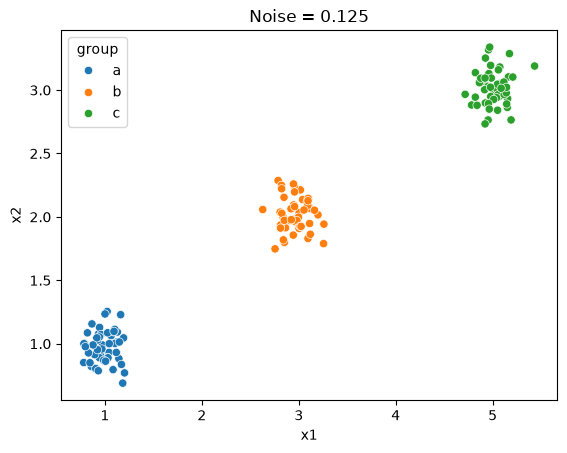

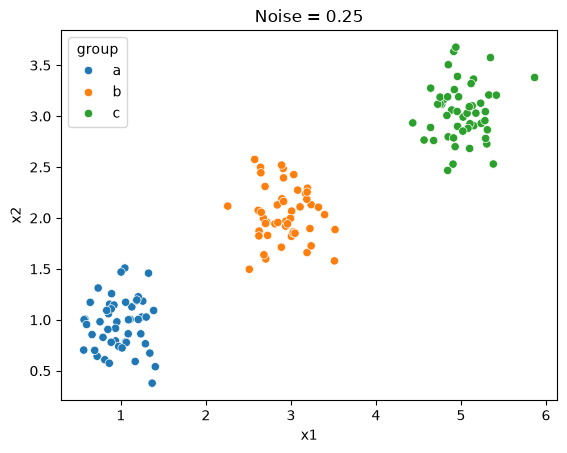

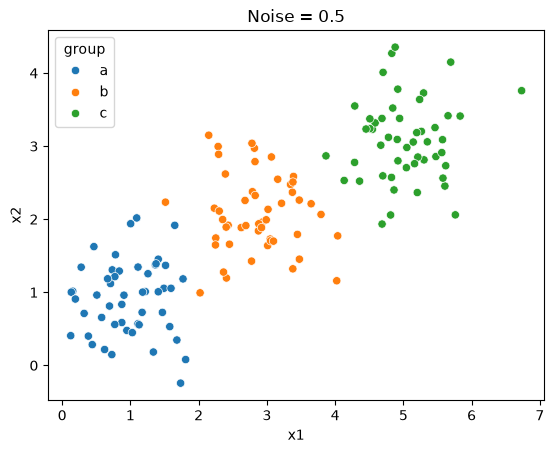

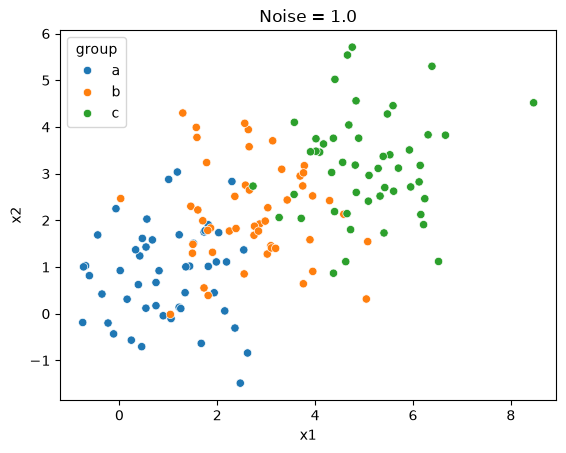

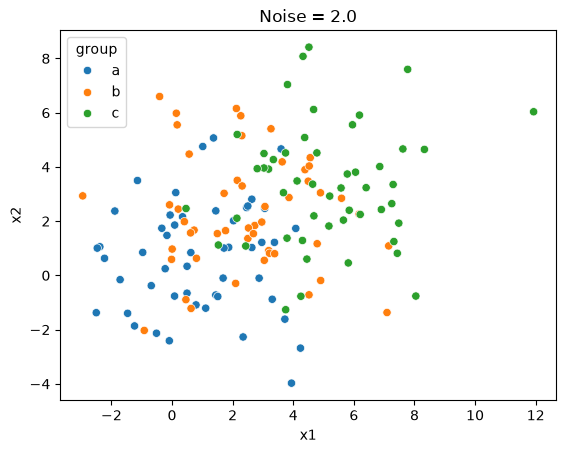

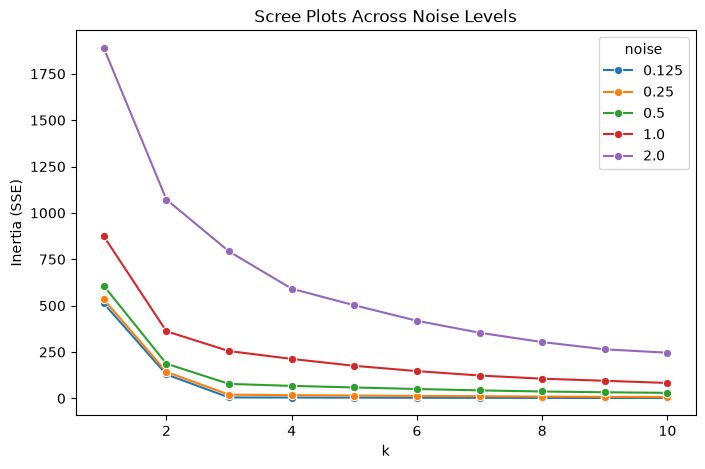

In [6]:
# Your Phase 2 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# make scatterplot
sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group')
plt.title("Noise = 0.125")
plt.show()
sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group')
plt.title("Noise = 0.25")
plt.show()
sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group')
plt.title("Noise = 0.5")
plt.show()
sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group')
plt.title("Noise = 1.0")
plt.show()
sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group')
plt.title("Noise = 2.0")
plt.show()



# Combined scree plot across all five noise levels
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

ks = np.arange(1, 11)
scree_data = []

for noise, d in datasets.items():
    X_sim = d[['x1', 'x2']]

    for k in ks:
        km = KMeans(
            n_clusters=k,
            max_iter=300,
            n_init=10,
            random_state=0
        )
        km.fit(X_sim)

        scree_data.append({
            'noise': str(noise),
            'k': k,
            'SSE': km.inertia_
        })

df_scree = pd.DataFrame(scree_data)

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df_scree,
    x='k',
    y='SSE',
    hue='noise',
    marker='o'
)
plt.title("Scree Plots Across Noise Levels")
plt.xlabel("k")
plt.ylabel("Inertia (SSE)")
plt.show()


Q2. At lower noise levels, the three groups are clustered together in their own distinct area, but as noise increases they are seen gradually spreading out to the point where the three groups are all overlaping with each other.

Q3. As noise increases, the elbow of the scree plot becomes less clear. The datasets that have a low noise such as 0.125 and 0.25, the elbow, k = 3, is easy to identify which lets us tknow that 3 clusters was a good choice. However as noise increases, the data points becomes more spread out and the curve becomes less sharp and smoother, making it harder to determine the best number of clusters. Higher noise makes it harder to use the scree plot to choose k. The SSE values also increase with noise, and we can tell that by looking at the tick values on the vertical axis, which causes the vertical scales to differ across the plots.

Q4. The elbow shows the point in which adding more clusters stops significantly reducing the SSE. In this simulation, we see that the elbow is around k=3 because the data has 3 original groups. When k is less than 3, adding clusters allows you to separate the groups and significantly reduce the SSE. However when you increase k, after k = 3, adding more clusters only slightly reduces the SSE because the three groups are already separated, which is why the curve gets flatter after the elbow. 

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5744,5744,2020,Yemen,NaN,NaN,NaN,NaN
5778,5778,2020,"Yemen, North",NaN,NaN,NaN,NaN
5812,5812,2020,Yugoslavia,NaN,NaN,NaN,NaN
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


number of countries:  148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


number of duplicated rows:  0


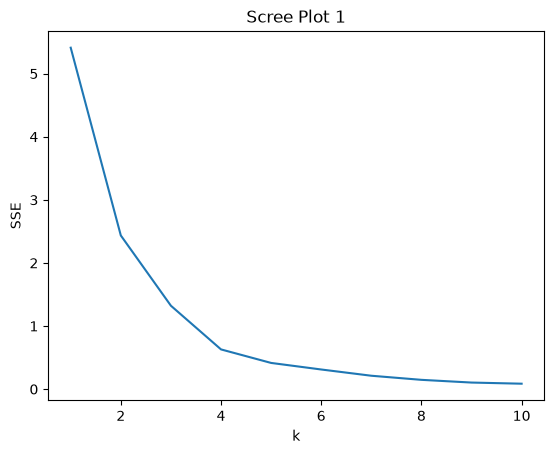

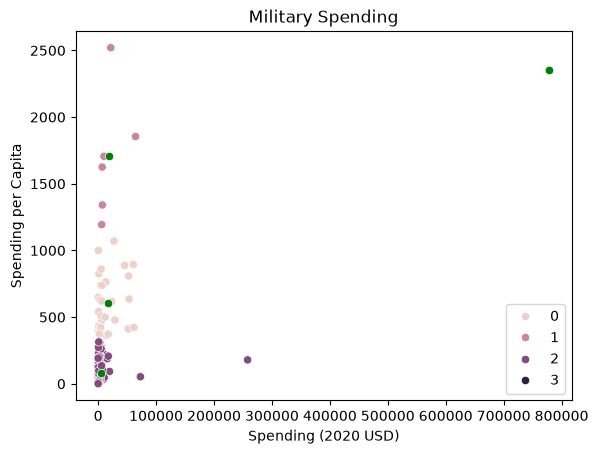

Spending (2020 USD)                                              \
                            count           mean           std            min   
cluster_part2                                                                   
0                            30.0   17077.591354  20583.053357     405.790494   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                           111.0    4859.185065  25405.739131       8.622460   
3                             1.0  778397.200000           NaN  778397.200000   

                                                                           \
                         25%            50%            75%            max   
cluster_part2                                                               
0                2294.039665    5857.060906   26296.001003   61712.537169   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2                 130.010211     382.464677    2297.032353  257973.429834   
3              778397.200000  778397.200000  778397.200000  778397.200000   

              Spending per Capita                                        \
                            count         mean         std          min   
cluster_part2                                                             
0                            30.0   607.478618  206.928757   362.467076   
1                             6.0  1706.721916  466.375705  1193.598730   
2                           111.0    80.061470   83.501824     0.580129   
3                             1.0  2351.631858         NaN  2351.631858   

                                                                   
                       25%          50%          75%          max  
cluster_part2                                                      
0               422.208252   579.004604   757.328513  1070.623322  
1              1412.083201  1665.447478  1817.219993  2520.398541  
2                14.880549    47.056944   125.387558   314.201312  
3              2351.631858  2351.631858  2351.631858  2351.631858

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster_part2
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3


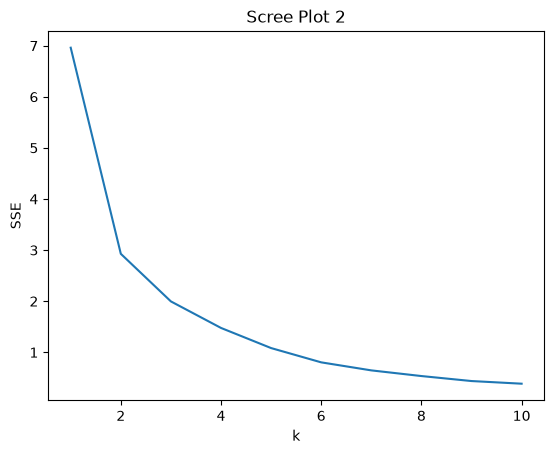

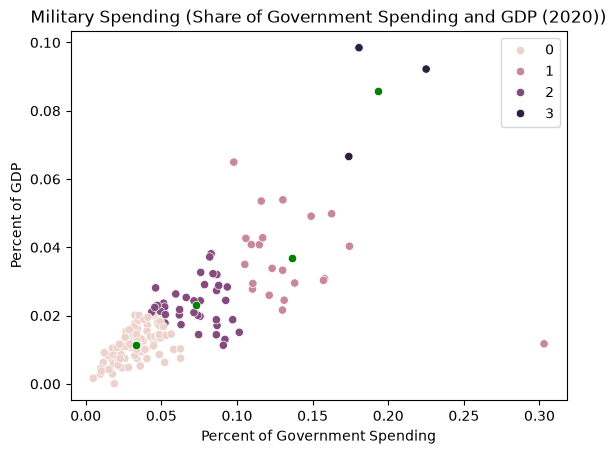

Percent of Government Spending                                \
                                       count      mean       std       min   
cluster_part3                                                                
0                                       86.0  0.033019  0.013198  0.004896   
1                                       22.0  0.136158  0.042661  0.097882   
2                                       37.0  0.072669  0.016870  0.043592   
3                                        3.0  0.193209  0.027779  0.173924   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
cluster_part3                                                          
0              0.022977  0.032821  0.042267  0.062685           86.0   
1              0.111561  0.126638  0.146304  0.303027           22.0   
2              0.059520  0.075583  0.086497  0.101501           37.0   
3              0.177289  0.180654  0.202852  0.225050            3.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
cluster_part3                                                               
0              0.011394  0.004816  0.000054  0.007542  0.011341  0.014507   
1              0.036932  0.012381  0.011742  0.029458  0.034419  0.042766   
2              0.023079  0.006411  0.011317  0.018801  0.022408  0.027340   
3              0.085760  0.016886  0.066600  0.079405  0.092211  0.095341   

                         
                    max  
cluster_part3            
0              0.020535  
1              0.064961  
2              0.038118  
3              0.098470

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster_part2,cluster_part3
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3,2


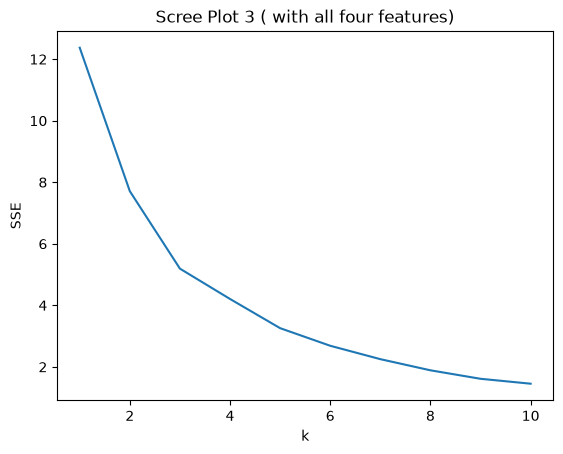

Spending (2020 USD)                                             \
                            count           mean            std          min   
cluster_part4                                                                  
0                           111.0    7086.472777   26479.379918     8.622460   
1                            31.0    8786.086602   17901.909108   162.373364   
2                             6.0  147964.582042  309635.189564  6095.708713   

                                                                       \
                       25%           50%           75%            max   
cluster_part4                                                           
0               130.010211    567.650747   3910.107493  257973.429834   
1               467.787851   1404.787234   7739.166193   72937.064048   
2              7700.424616  15897.570598  53872.942442  778397.200000   

              Spending per Capita                                        \
                            count         mean         std          min   
cluster_part4                                                             
0                           111.0   196.926833  267.788506     0.580129   
1                            31.0   212.689100  257.841988    18.297119   
2                             6.0  1875.150751  489.800206  1193.598730   

                                                                   \
                       25%          50%          75%          max   
cluster_part4                                                       
0                14.880549    67.083417   295.296094  1341.058851   
1                46.485917   135.459845   217.333791   998.966186   
2              1645.301864  1780.059564  2227.318999  2520.398541   

              Percent of Government Spending                                \
                                       count      mean       std       min   
cluster_part4                                                                
0                                      111.0  0.040350  0.019320  0.004896   
1                                       31.0  0.122985  0.043927  0.076005   
2                                        6.0  0.135351  0.055392  0.081976   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
cluster_part4                                                          
0              0.026712  0.037952  0.050505  0.092044          111.0   
1              0.093093  0.114776  0.134663  0.303027           31.0   
2              0.101034  0.113271  0.164503  0.225050            6.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
cluster_part4                                                               
0              0.013419  0.005996  0.000054  0.008873  0.013589  0.017769   
1              0.033492  0.011449  0.011742  0.027560  0.032024  0.040531   
2              0.062634  0.028275  0.029429  0.041272  0.059257  0.085398   

                         
                    max  
cluster_part4            
0              0.028132  
1              0.066600  
2              0.098470

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster_part2,cluster_part3,cluster_part4
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3,2,2


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# load the csv file
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
df_year_2020 = df[df['Year'] == 2020]  # only year 2020
display(df_year_2020)
df_no_missing = df_year_2020.dropna().copy()
print("number of countries: ",df_no_missing['Country'].value_counts().sum()) # verify number of countries
display(df_no_missing)
print("number of duplicated rows: ",df_no_missing['Country'].duplicated().sum())
df_no_missing.dtypes


# min max scaling spending(2020 USD) and spending per capita
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_no_missing.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins)/ ranges
X.agg(["min", "max"])

# make scree plot
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot 1",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

# scatterplot
model = KMeans(n_clusters = 4, n_init=10, random_state = 0).fit(X)
df_no_missing["cluster_part2"] = model.labels_

centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()

ax = sns.scatterplot(
    data=df_no_missing,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster_part2"
)
sns.scatterplot(x=centers[:,0], y=centers[:,1], color="green", ax=ax)
plt.title("Military Spending")
plt.show()

# describe table
display(
    df_no_missing.groupby("cluster_part2")[
        ["Spending (2020 USD)", "Spending per Capita"]
    ].describe()
)

display(
    df_no_missing[
        df_no_missing["Country"].str.contains("United States", case=False)
    ]
)


# percent of government spending and percent of gpd

features = ["Percent of Government Spending", "Percent of GDP"]

unscaled = df_no_missing.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins

X = (unscaled - mins) / ranges

X.agg(["min", "max"])

ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot 2",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
df_no_missing["cluster_part3"] = model.labels_

centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()

ax = sns.scatterplot(
    data=df_no_missing,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster_part3"
)

sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)

plt.title("Military Spending (Share of Government Spending and GDP (2020))")
plt.show()

display(
    df_no_missing.groupby("cluster_part3")[
        ["Percent of Government Spending", "Percent of GDP"]
    ].describe()
)

display(
    df_no_missing[
        df_no_missing["Country"].str.contains("United States", case=False)
    ]
)

# k means clustering with all 4
features = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

unscaled = df_no_missing.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins)/ ranges
X.agg(["min", "max"])

# make scree plot
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot 3 ( with all four features)",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
df_no_missing["cluster_part4"] = model.labels_

pd.set_option("display.max_columns", None)

display(
    df_no_missing.groupby("cluster_part4")[
        ["Spending (2020 USD)", "Spending per Capita",
         "Percent of Government Spending", "Percent of GDP"]
    ].describe()
)

display(
    df_no_missing[
        df_no_missing["Country"].str.contains("United States", case=False)
    ]
)

Q1. No I don't believe additional cleaning was needed since missing values were dropped, and I also went in to check if the data types made sense for the values and if there were any duplicate rows. 

Q2. The describe table shows the four clusters and the difference in total military spending and spending per capita. We're able to see that Cluster 2 contains the most countries with a total of 111 countries, but has the lowest spending per capita. Compared to Cluster 1, which has a total of 6 countries but the highest average spending per capita. Cluster 3 only contains the United States and that has the highest total military spending. K-means placed the United States in its own cluster due to the fact that its total spending was much higher than the other countries. I think that the clusters are showing that countries differ in both their military spending and their spending per capita. 

Q3. Cluster 0, while containing the most countries, 86, it has the lowest average percentages, while Cluster 3 with only 3 countries has the highest average percentages. The united states is in cluster 2 in this analysis. We're able to see that when clustering countries based on their relative military spending we get different groupings compared to clustering them by total spending and spending per capita. It's possible for a country to spend a large amount of money on its military without necessarily spending a larger percentage of its government budget on the military.

Q4. This time around when using 4 variables, three clusters seemed to be a better fit. I was able to see that despite Cluster 0 and 1 having the most countries it had significantly lower military spending compared to Cluster 2 who only had 6 countries but had generally the highest military spending as a whole. Compared to the previous analyses, when using all four variables, it has more factors to consider including the total amount spent on military as well as the share of the government spending and GDP devoted to it. Because it has more factors to consider, it resulted in there being different clusters memberships because the countries were grouped based on all four of those measures as opposed to only two.

Q5. Yes, the K-MC clustering found useful patterns. Through this I was able to see that most countries fell into clusters with lower military spending, while only a few countries were grouped in the group that had the highest spending and devoted more percentages of their government budgest and GDP to the military. Along with that, the results also show that clustering is impacted based on the variables that are used. This shows us that you can't just look at two measures or three measures or even four measures, because depending on how you group them you get different results, which might tell you something different.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements for this assignment that AI suggested for me were pertaining to cleaning up the code to reduce redundancies and maintaining good code hygiene. For part one, I initally created a scree plot for each individual noise level and while correct it was a bit repetitive and redundant. In the moment while I did notice that, I wasn't exactly sure how I would adjust it. Gemini was able to create an alternate solution that essentially was doing the same thing that I was but put it all on one plot so I only had to do it once rather than 5 individual times. Gemini also suggested other good code hygiene practices, which in normal cases when it comes to variables I would rename it. However, since in this case my output wouldn't really be changed if I reused/ overwrote the variables, I didn't think it was that important, but I do think it's a good practice to keep in mind. The only limitations, if you could consider it that, is that I do think at times Gemini can be a little bit over technical. I do think that it has the tendency to over complicate or look further into things than it actually has to for the specific scope of the problem. I verified the final solution by, since it wasn't really saying that I had anything wrong with my initial output, I just double checked to ensure that I was getting the same results. 